# 03 — Tree models: Random Forest and gradient boosting

**Goal:** non-linear regression models for RUL, compared with the linear baseline on exactly the same target, split, validation points and metrics.

- **Features:** the agreed v2 table from Aryan's `features.py`: `cycle` + 14 informative sensors + trailing 10-cycle rolling mean, std and slope (57 inputs).
- **Models:** `RandomForestRegressor` and gradient boosting. **XGBoost is not installed**, so boosting uses scikit-learn's `HistGradientBoostingRegressor` (recorded in the results).
- **Protocol:** `docs/EVALUATION_PROTOCOL.md`: no RUL cap, 80/20 split by engine (seed 42), scored on the 100 validation cut-off rows. Settings are chosen by **validation RMSE**; the test set is scored **once per model family**, at the end.

Run this notebook from the `notebooks/` folder.

In [1]:
import ast
import sys
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import sklearn
from scipy import stats
from sklearn.linear_model import ElasticNet
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

PROJECT_ROOT = Path.cwd().parent
sys.path.insert(0, str(PROJECT_ROOT / "src"))

from rul_prediction.data import load_cmapss_file, load_rul_file
from rul_prediction.features import (
    DEFAULT_WINDOW,
    add_rolling_features,
    model_feature_columns,
    select_informative_sensors,
)
from rul_prediction.metrics import score_predictions
from rul_prediction.models.tree_models import importance_table, make_gradient_boosting, make_random_forest
from rul_prediction.splits import DEFAULT_SEED, sample_cutoff_rows, split_by_engine, split_engine_ids
from rul_prediction.targets import add_train_rul, attach_test_rul, last_observed_rows

RAW_DIR = PROJECT_ROOT / "data" / "raw"
FIGURES_DIR = PROJECT_ROOT / "reports" / "figures"
RESULTS_DIR = PROJECT_ROOT / "reports" / "results"
FIGURES_DIR.mkdir(parents=True, exist_ok=True)
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

## 1. Target, split, features and validation points

Same pipeline as the linear baseline: shared target and split, sensor selection fitted on the 80 training engines, rolling features built per split, and the 100 validation cut-off rows sampled **after** the features. The assert checks the points against `docs/fd001_validation_cutoffs.csv`.

In [2]:
train = add_train_rul(load_cmapss_file(RAW_DIR / "train_FD001.txt"))
train_ids, val_ids = split_engine_ids(train["engine_id"])
train_raw, val_raw = split_by_engine(train, val_ids)

sensors = select_informative_sensors(train_raw)
train_df = add_rolling_features(train_raw, sensors)
val_df = add_rolling_features(val_raw, sensors)
val_points = sample_cutoff_rows(val_df)

expected_points = pd.read_csv(PROJECT_ROOT / "docs" / "fd001_validation_cutoffs.csv")
pd.testing.assert_frame_equal(val_points[["engine_id", "cycle", "rul"]], expected_points)

FEATURES = model_feature_columns(sensors, DEFAULT_WINDOW)
FEATURE_SET_NAME = f"v2: cycle + {len(sensors)} sensors + rolling mean/std/slope w{DEFAULT_WINDOW} ({len(FEATURES)})"

print(f"train engines: {len(train_ids)}, rows: {len(train_df)}")
print(f"validation engines: {len(val_ids)}, rows: {len(val_df)}, cut-off points: {len(val_points)}")
print("features:", FEATURE_SET_NAME)

train engines: 80, rows: 16390
validation engines: 20, rows: 4241, cut-off points: 100
features: v2: cycle + 14 sensors + rolling mean/std/slope w10 (57)


## 2. Two kinds of tree ensemble

| | Random Forest | Gradient boosting |
|---|---|---|
| How | Many deep trees, each on a bootstrap sample of rows and a random subset of features; predictions **averaged** | Small trees added **one after another**, each fitting the errors left by the trees before it |
| Bias–variance | Averaging mainly lowers **variance** (each deep tree overfits differently) | Adding trees mainly lowers **bias** (each step corrects what is still wrong) |
| Main knobs | `min_samples_leaf` (bigger = smoother trees), `max_features` (share of features per split) | `learning_rate` (size of each step), `max_iter` (number of trees), `max_depth` |

Unlike a straight line, a tree can learn "flat for a long time, then rising", which the linear baseline could not. Trees need no feature scaling: a split only compares a value with a threshold.

**Basic model first:** a default Random Forest is fitted before any tuning and kept as the first result.

In [3]:
def fit_and_score(model, features=FEATURES):
    """Fit on the 80 training engines; score train rows, all validation rows and the 100 cut-offs."""
    start = time.perf_counter()
    model.fit(train_df[features], train_df["rul"])
    fit_seconds = time.perf_counter() - start
    cutoff = score_predictions(val_points["rul"], model.predict(val_points[features]))
    return model, {
        "val_mae": cutoff["mae"],
        "val_rmse": cutoff["rmse"],
        "val_n": cutoff["n"],
        "val_all_rows_rmse": score_predictions(val_df["rul"], model.predict(val_df[features]))["rmse"],
        "train_rmse": score_predictions(train_df["rul"], model.predict(train_df[features]))["rmse"],
        "fit_seconds": fit_seconds,
    }


DEFAULT_RF_PARAMS = {"n_estimators": 300}
_, default_rf_scores = fit_and_score(make_random_forest(**DEFAULT_RF_PARAMS))
pd.Series(default_rf_scores, name="default Random Forest").round(2)

val_mae               26.69
val_rmse              44.24
val_n                100.00
val_all_rows_rmse     44.03
train_rmse             6.17
fit_seconds           16.81
Name: default Random Forest, dtype: float64

## 3. Tune a few parameters on validation

Small grids on purpose (one fixed validation split is easy to overfit). The number of Random Forest trees is fixed at 300: more trees only make the average more stable, they do not change what each tree learns.

In [4]:
RF_GRID = [
    {"n_estimators": 300, "min_samples_leaf": leaf, "max_features": share}
    for leaf in [1, 5, 20]
    for share in [0.33, 1.0]
]
GB_GRID = [
    {"learning_rate": rate, "max_iter": trees, "max_depth": depth}
    for rate in [0.05, 0.1]
    for trees in [200, 500]
    for depth in [3, None]
]
FAMILIES = {
    "RandomForest": (make_random_forest, RF_GRID),
    "GradientBoosting": (make_gradient_boosting, GB_GRID),
}


def params_key(params):
    return tuple(sorted(params.items(), key=lambda item: item[0]))


rows, fitted = [], {}
for family, (factory, family_grid) in FAMILIES.items():
    for params in family_grid:
        model, scores = fit_and_score(factory(**params))
        fitted[(family, params_key(params))] = model
        rows.append({"model": family, "params": params, **scores})

grid = pd.DataFrame(rows)
grid.round(2).sort_values(["model", "val_rmse"])

,model,params,val_mae,val_rmse,val_n,val_all_rows_rmse,train_rmse,fit_seconds
6,GradientBoosting,"{'learning_rate': 0.05, 'max_iter': 200, 'max_...",26.12,40.17,100,43.02,29.66,0.41
10,GradientBoosting,"{'learning_rate': 0.1, 'max_iter': 200, 'max_d...",26.22,41.22,100,43.14,27.10,0.36
8,GradientBoosting,"{'learning_rate': 0.05, 'max_iter': 500, 'max_...",26.36,41.70,100,43.48,26.06,0.67
11,GradientBoosting,"{'learning_rate': 0.1, 'max_iter': 200, 'max_d...",26.43,41.77,100,43.76,13.33,1.23
13,GradientBoosting,"{'learning_rate': 0.1, 'max_iter': 500, 'max_d...",26.39,42.02,100,44.01,6.82,3.09
12,GradientBoosting,"{'learning_rate': 0.1, 'max_iter': 500, 'max_d...",26.66,42.06,100,43.78,22.55,0.64
7,GradientBoosting,"{'learning_rate': 0.05, 'max_iter': 200, 'max_...",25.90,42.11,100,43.48,17.97,1.43
9,GradientBoosting,"{'learning_rate': 0.05, 'max_iter': 500, 'max_...",25.88,42.67,100,43.89,11.49,3.36
4,RandomForest,"{'n_estimators': 300, 'min_samples_leaf': 20, ...",25.03,40.17,100,42.62,21.15,3.33
0,RandomForest,"{'n_estimators': 300, 'min_samples_leaf': 1, '...",25.19,40.93,100,42.80,6.74,6.76


## 4. Choose on validation only, and compare with the linear baseline

Best setting per family by validation RMSE. The linear baseline row is read from `reports/results/linear_baseline_results.csv` (v2 Elastic Net), not retyped.

In [5]:
best_per_family = grid.loc[grid.groupby("model")["val_rmse"].idxmin()].sort_values("val_rmse").set_index("model")
chosen_models = {
    family: fitted[(family, params_key(row["params"]))] for family, row in best_per_family.iterrows()
}
best_family = best_per_family.index[0]

linear = pd.read_csv(RESULTS_DIR / "linear_baseline_results.csv")
# The linear baseline is the v2 row with the lowest validation RMSE (the model chosen in 03_linear_baseline).
linear_v2 = linear[linear["feature_set"] == "v2"]
linear_baseline = linear_v2.loc[linear_v2["val_rmse"].idxmin()]

comparison = pd.concat([
    pd.DataFrame([{
        "model": f"Linear baseline v2 ({linear_baseline['model']})",
        "val_mae": linear_baseline["val_mae"],
        "val_rmse": linear_baseline["val_rmse"],
    }]),
    best_per_family.reset_index()[["model", "params", "val_mae", "val_rmse", "train_rmse", "val_all_rows_rmse"]],
], ignore_index=True)
print("best tree family on validation:", best_family)
comparison.round(2)

best tree family on validation: RandomForest


,model,val_mae,val_rmse,params,train_rmse,val_all_rows_rmse
0,Linear baseline v2 (ElasticNet),31.66,41.77,NaN,NaN,NaN
1,RandomForest,25.03,40.17,"{'n_estimators': 300, 'min_samples_leaf': 20, ...",21.15,42.62
2,GradientBoosting,26.12,40.17,"{'learning_rate': 0.05, 'max_iter': 200, 'max_...",29.66,43.02


## 4b. Do the trees use the rolling features? (validation-only ablation)

The linear baseline gained nothing from the rolling features once `cycle` was included. Trees can combine features non-linearly, so the question is re-checked here with each family's chosen settings. **Analysis only:** not used to choose the model, never scored on the test set.

In [6]:
ablation_inputs = {
    "v2 full (cycle + sensors + rolling)": FEATURES,
    "cycle + 14 raw sensors (no rolling)": ["cycle"] + sensors,
    "v2 without cycle (sensors + rolling)": [f for f in FEATURES if f != "cycle"],
}
ablation_rows = []
for family, (factory, _) in FAMILIES.items():
    params = best_per_family.loc[family, "params"]
    for name, columns in ablation_inputs.items():
        _, scores = fit_and_score(factory(**params), columns)
        ablation_rows.append({"model": family, "inputs": name, "n_features": len(columns),
                              "val_mae": scores["val_mae"], "val_rmse": scores["val_rmse"]})
ablation = pd.DataFrame(ablation_rows).set_index(["model", "inputs"])
ablation.round(2)

n_features  val_mae  \
model            inputs                                                      
RandomForest     v2 full (cycle + sensors + rolling)           57    25.03   
                 cycle + 14 raw sensors (no rolling)           15    24.40   
                 v2 without cycle (sensors + rolling)          56    28.27   
GradientBoosting v2 full (cycle + sensors + rolling)           57    26.12   
                 cycle + 14 raw sensors (no rolling)           15    24.02   
                 v2 without cycle (sensors + rolling)          56    29.20   

                                                       val_rmse  
model            inputs                                          
RandomForest     v2 full (cycle + sensors + rolling)      40.17  
                 cycle + 14 raw sensors (no rolling)      37.13  
                 v2 without cycle (sensors + rolling)     43.60  
GradientBoosting v2 full (cycle + sensors + rolling)      40.17  
                 cycle + 14 raw sensors (no rolling)      36.44  
                 v2 without cycle (sensors + rolling)     43.38

## 5. Diagnostics on validation

Predicted vs actual for the linear baseline and both chosen tree models on the same 100 points, then residual checks for the best tree model. Residual = actual RUL − predicted RUL (positive = the model said the engine fails sooner than it does). The linear baseline is refitted from its saved hyperparameters (deterministic), only to plot it.

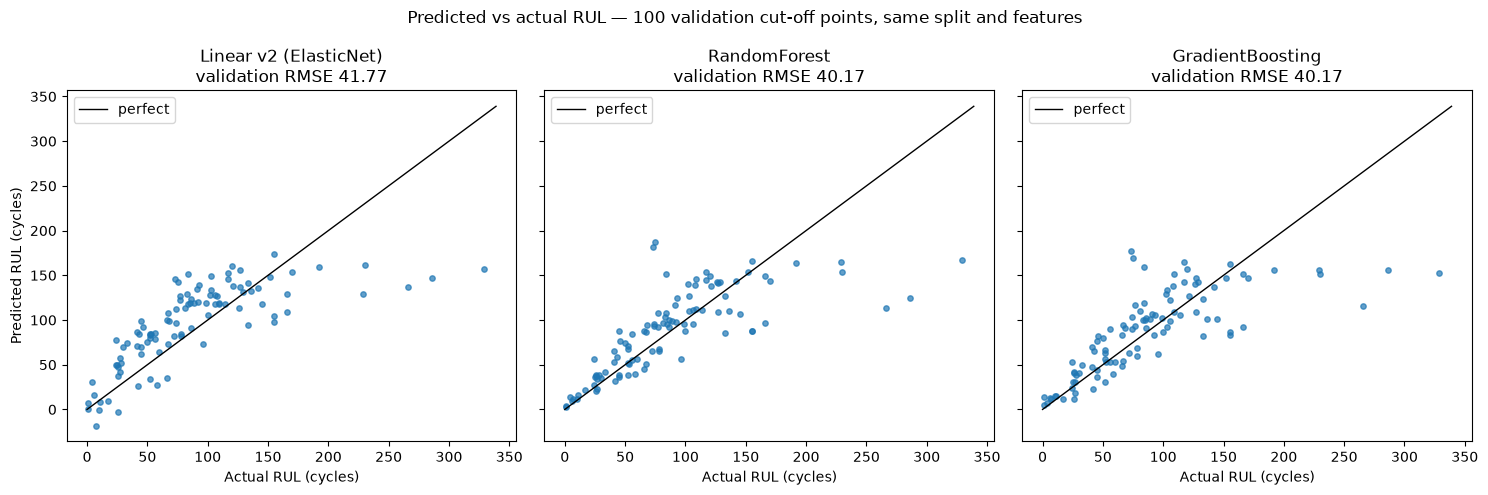

In [7]:
linear_params = ast.literal_eval(linear_baseline["params"])  # saved by 03_linear_baseline as a dict literal
linear_model = make_pipeline(StandardScaler(), ElasticNet(**linear_params, max_iter=50_000))
linear_model.fit(train_df[FEATURES], train_df["rul"])

predictions = {f"Linear v2 ({linear_baseline['model']})": linear_model.predict(val_points[FEATURES])}
predictions.update({family: model.predict(val_points[FEATURES]) for family, model in chosen_models.items()})

limit = max(val_points["rul"].max(), max(p.max() for p in predictions.values())) + 10
fig, axes = plt.subplots(1, 3, figsize=(15, 5), sharex=True, sharey=True)
for ax, (name, pred) in zip(axes, predictions.items()):
    rmse = score_predictions(val_points["rul"], pred)["rmse"]
    ax.scatter(val_points["rul"], pred, s=15, alpha=0.7)
    ax.plot([0, limit], [0, limit], color="black", linewidth=1, label="perfect")
    ax.set_title(f"{name}\nvalidation RMSE {rmse:.2f}")
    ax.set_xlabel("Actual RUL (cycles)")
    ax.legend(loc="upper left")
axes[0].set_ylabel("Predicted RUL (cycles)")
fig.suptitle("Predicted vs actual RUL — 100 validation cut-off points, same split and features")
fig.tight_layout()
fig.savefig(FIGURES_DIR / "tree_vs_linear_predicted_vs_actual.png", dpi=150)
plt.show()

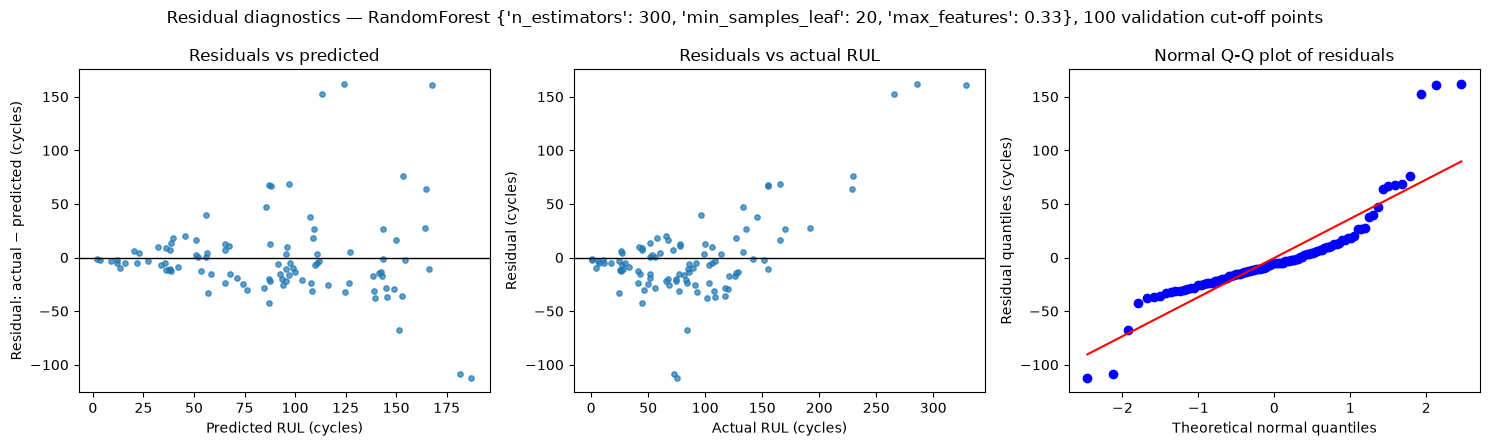

Linear v2 (ElasticNet): highest prediction 173.6, negative predictions 3 of 100
RandomForest: highest prediction 187.2, negative predictions 0 of 100
GradientBoosting: highest prediction 177.5, negative predictions 0 of 100


In [8]:
best_pred = predictions[best_family]
residuals = val_points["rul"] - best_pred

fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))
axes[0].scatter(best_pred, residuals, s=15, alpha=0.7)
axes[0].axhline(0, color="black", linewidth=1)
axes[0].set_xlabel("Predicted RUL (cycles)")
axes[0].set_ylabel("Residual: actual − predicted (cycles)")
axes[0].set_title("Residuals vs predicted")

axes[1].scatter(val_points["rul"], residuals, s=15, alpha=0.7)
axes[1].axhline(0, color="black", linewidth=1)
axes[1].set_xlabel("Actual RUL (cycles)")
axes[1].set_ylabel("Residual (cycles)")
axes[1].set_title("Residuals vs actual RUL")

stats.probplot(residuals, dist="norm", plot=axes[2])
axes[2].set_title("Normal Q-Q plot of residuals")
axes[2].set_xlabel("Theoretical normal quantiles")
axes[2].set_ylabel("Residual quantiles (cycles)")

fig.suptitle(f"Residual diagnostics — {best_family} {best_per_family.loc[best_family, 'params']}, 100 validation cut-off points")
fig.tight_layout()
fig.savefig(FIGURES_DIR / "tree_best_residuals.png", dpi=150)
plt.show()

for name, pred in predictions.items():
    print(f"{name}: highest prediction {pred.max():.1f}, negative predictions {(pred < 0).sum()} of {len(pred)}")

## 6. Feature importance

**Permutation importance:** shuffle one column of the 100 validation points and measure how much RMSE rises (10 repeats). It is computed on validation rows, so it reflects what generalises. Random Forest also has **impurity importance** (how much each feature reduced training error inside the trees), which is biased towards features with many distinct values.

Read with care:
- Importance shows what **the model relies on**, not what **causes** engine failure.
- Correlated features share credit: shuffling one rolling mean barely hurts if its raw sensor still carries the same signal, so both can look unimportant.

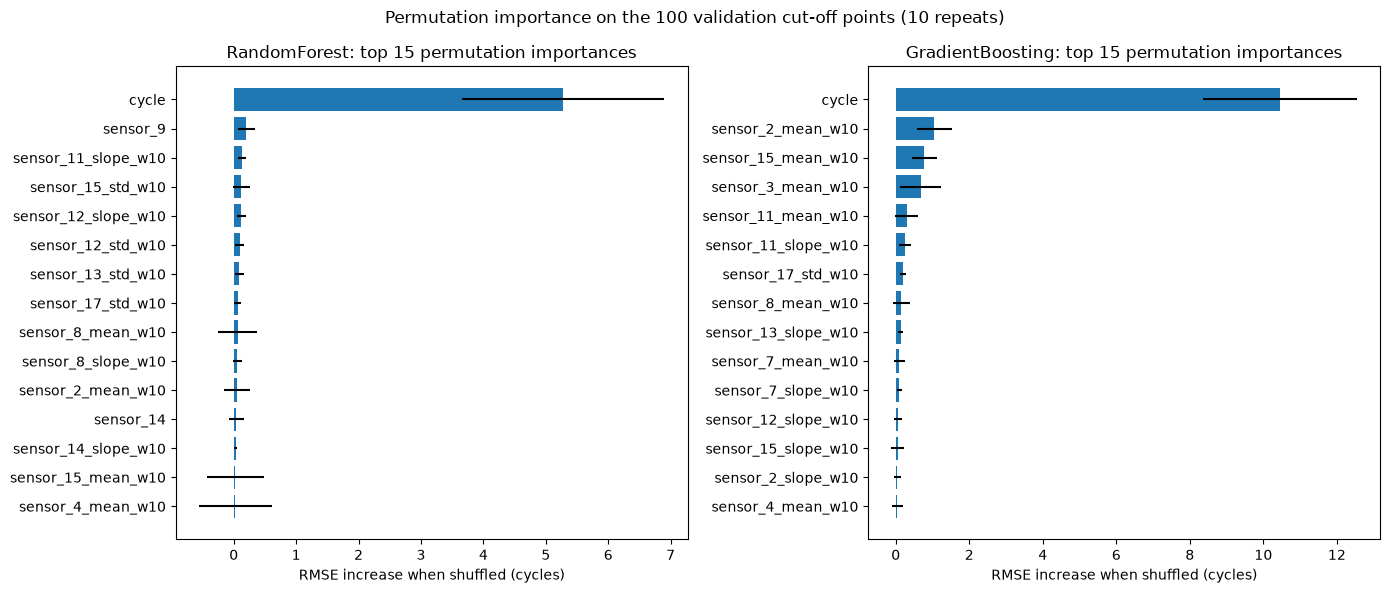

rmse_increase_mean  rmse_increase_std  \
                 feature                                                      
RandomForest     cycle                             5.279              1.618   
                 sensor_9                          0.202              0.134   
                 sensor_11_slope_w10               0.130              0.063   
                 sensor_15_std_w10                 0.124              0.129   
                 sensor_12_slope_w10               0.124              0.067   
                 sensor_12_std_w10                 0.095              0.077   
                 sensor_13_std_w10                 0.091              0.066   
                 sensor_17_std_w10                 0.066              0.058   
                 sensor_8_mean_w10                 0.061              0.310   
                 sensor_8_slope_w10                0.060              0.073   
GradientBoosting cycle                            10.452              2.087   
                 sensor_2_mean_w10                 1.047              0.483   
                 sensor_15_mean_w10                0.777              0.339   
                 sensor_3_mean_w10                 0.680              0.559   
                 sensor_11_mean_w10                0.295              0.317   
                 sensor_11_slope_w10               0.246              0.156   
                 sensor_17_std_w10                 0.195              0.092   
                 sensor_8_mean_w10                 0.152              0.236   
                 sensor_13_slope_w10               0.132              0.064   
                 sensor_7_mean_w10                 0.101              0.139   

                                      impurity_importance  
                 feature                                   
RandomForest     cycle                              0.325  
                 sensor_9                           0.008  
                 sensor_11_slope_w10                0.001  
                 sensor_15_std_w10                  0.004  
                 sensor_12_slope_w10                0.001  
                 sensor_12_std_w10                  0.003  
                 sensor_13_std_w10                  0.003  
                 sensor_17_std_w10                  0.002  
                 sensor_8_mean_w10                  0.007  
                 sensor_8_slope_w10                 0.002  
GradientBoosting cycle                                NaN  
                 sensor_2_mean_w10                    NaN  
                 sensor_15_mean_w10                   NaN  
                 sensor_3_mean_w10                    NaN  
                 sensor_11_mean_w10                   NaN  
                 sensor_11_slope_w10                  NaN  
                 sensor_17_std_w10                    NaN  
                 sensor_8_mean_w10                    NaN  
                 sensor_13_slope_w10                  NaN  
                 sensor_7_mean_w10                    NaN

In [9]:
importances = {
    family: importance_table(model, val_points[FEATURES], val_points["rul"])
    for family, model in chosen_models.items()
}

TOP_N = 15
fig, axes = plt.subplots(1, 2, figsize=(14, 6))
for ax, (family, table) in zip(axes, importances.items()):
    top = table.head(TOP_N).iloc[::-1]
    ax.barh(top.index, top["rmse_increase_mean"], xerr=top["rmse_increase_std"], color="tab:blue")
    ax.set_xlabel("RMSE increase when shuffled (cycles)")
    ax.set_title(f"{family}: top {TOP_N} permutation importances")
fig.suptitle("Permutation importance on the 100 validation cut-off points (10 repeats)")
fig.tight_layout()
fig.savefig(FIGURES_DIR / "tree_permutation_importance.png", dpi=150)
plt.show()

pd.concat({family: table.head(10) for family, table in importances.items()}).round(3)

## 7. Final test evaluation (run once per family)

The chosen settings above are fixed. Test features are built from `test_FD001.txt` alone with the sensor list chosen on the training engines. Each test engine is predicted at its last observed cycle and joined to `RUL_FD001.txt` by `engine_id`. Do not change a model after reading its number.

In [10]:
test_features = add_rolling_features(load_cmapss_file(RAW_DIR / "test_FD001.txt"), sensors)
test_points = attach_test_rul(last_observed_rows(test_features), load_rul_file(RAW_DIR / "RUL_FD001.txt"))

test_scores = {
    family: score_predictions(test_points["rul"], model.predict(test_points[FEATURES]))
    for family, model in chosen_models.items()
}
pd.DataFrame(test_scores).T

,mae,rmse,n
RandomForest,18.949857,25.877081,100.0
GradientBoosting,18.542985,25.331565,100.0


## 8. Save results

Everything below is written from the variables above, so no number is typed by hand.

In [11]:
split_description = f"engine ID 80/20, seed {DEFAULT_SEED}, 100 val cut-offs (docs/fd001_validation_cutoffs.csv)"
IMPLEMENTATIONS = {
    "RandomForest": "sklearn RandomForestRegressor (n_jobs=-1)",
    "GradientBoosting": "sklearn HistGradientBoostingRegressor (XGBoost not installed; early_stopping=False)",
}

summary = best_per_family.reset_index().assign(
    implementation=lambda df: df["model"].map(IMPLEMENTATIONS),
    features=FEATURE_SET_NAME,
    target="RUL = last cycle - cycle, no cap",
    split=split_description,
    seed=DEFAULT_SEED,
    test_mae=lambda df: df["model"].map(lambda family: test_scores[family]["mae"]),
    test_rmse=lambda df: df["model"].map(lambda family: test_scores[family]["rmse"]),
    test_n=lambda df: df["model"].map(lambda family: test_scores[family]["n"]),
)

grid.to_csv(RESULTS_DIR / "tree_models_grid.csv", index=False)
summary.to_csv(RESULTS_DIR / "tree_models_results.csv", index=False)
ablation.to_csv(RESULTS_DIR / "tree_models_ablation.csv")
pd.concat(importances, names=["model"]).to_csv(RESULTS_DIR / "tree_models_importance.csv")

LOG_FILES = {"RandomForest": "tree_random_forest_experiment_log.md", "GradientBoosting": "tree_gradient_boosting_experiment_log.md"}
GRIDS_TEXT = {"RandomForest": f"{RF_GRID}", "GradientBoosting": f"{GB_GRID}"}


def write_experiment_log(family):
    row, scores = best_per_family.loc[family], test_scores[family]
    log = f"""# Experiment log — {family}

- **Owner:** Srijan
- **Notebook:** notebooks/03_tree_models.ipynb
- **Question:** Does a non-linear tree ensemble beat the linear baseline on the shared protocol?
- **Dataset/subset:** FD001
- **Split protocol / engine IDs:** {split_description}; validation engines {val_ids}
- **Target settings (including any RUL cap):** RUL = last cycle - cycle, no cap
- **Features or window length:** {FEATURE_SET_NAME}
- **Model:** {IMPLEMENTATIONS[family]}
- **Hyperparameters:** {row["params"]} (chosen by validation RMSE); grid: {GRIDS_TEXT[family]}
- **Random seed:** {DEFAULT_SEED} (split, cut-offs and model)
- **Validation MAE / RMSE (cycles, 100 cut-offs):** {row["val_mae"]:.2f} / {row["val_rmse"]:.2f}
- **Test MAE / RMSE (cycles, 100 engines, run once):** {scores["mae"]:.2f} / {scores["rmse"]:.2f}
- **Training time / hardware:** {row["fit_seconds"]:.1f} s fit on the 80 training engines, local CPU; scikit-learn {sklearn.__version__}
- **Plots/results file:** reports/figures/tree_vs_linear_predicted_vs_actual.png, reports/figures/tree_best_residuals.png, reports/figures/tree_permutation_importance.png, reports/results/tree_models_*.csv
- **What changed from previous experiment:** model family (linear baseline v2 -> {family}); same features, split and metrics
- **Interpretation:** see the Findings section of the notebook
- **Limitations / next experiment:** Random Forest and boosting tie on validation RMSE; 20 validation engines, so gaps of a few cycles may be noise; chosen settings sit at the edge of the grid (not widened after the test run); RUL cap or refitting on all 100 training engines only as separate logged team decisions
"""
    (RESULTS_DIR / LOG_FILES[family]).write_text(log)


for family in FAMILIES:
    write_experiment_log(family)
summary[["model", "params", "val_mae", "val_rmse", "test_mae", "test_rmse", "fit_seconds"]].round(2)

,model,params,val_mae,val_rmse,test_mae,test_rmse,fit_seconds
0,RandomForest,"{'n_estimators': 300, 'min_samples_leaf': 20, ...",25.03,40.17,18.95,25.88,3.33
1,GradientBoosting,"{'learning_rate': 0.05, 'max_iter': 200, 'max_...",26.12,40.17,18.54,25.33,0.41


## Findings

_All numbers come from the cell outputs above. Validation = the 100 shared cut-off points unless stated otherwise. Units: cycles._

| | Linear baseline v2 | Random Forest | Gradient boosting |
|---|---|---|---|
| Chosen settings | Elastic Net alpha 1, l1_ratio 0.5 | 300 trees, min_samples_leaf 20, max_features 0.33 | learning_rate 0.05, 200 trees, max_depth 3 |
| Validation MAE / RMSE | 31.66 / 41.77 | 25.03 / 40.17 | 26.12 / 40.17 |
| Test MAE / RMSE (scored once) | 23.61 / 29.04 | 18.95 / 25.88 | 18.54 / 25.33 |

**1. Both tree models beat the linear baseline. The MAE gain is clear; the RMSE gain is small.**
- *Validation:* MAE falls by about 5.5–6.6 cycles, but RMSE by only 1.6. With about 20 independent validation engines, a 1.6-cycle RMSE difference is within noise.
- *Test:* MAE is lower by 4.7 (Random Forest) and 5.1 (boosting), and RMSE by 3.2 and 3.7.
- *Why MAE moves more than RMSE:* the predicted-vs-actual plots show the trees sitting much closer to the diagonal for engines near failure (RUL below about 60), which lowers the average miss. All three models still miss the few engines with very large RUL (200–330, predicted at about 115–170). Those few large misses dominate RMSE.

**2. Random Forest and gradient boosting are tied.** Validation RMSE is 40.166 vs 40.168. Random Forest is lower by 0.0015 cycles, which is meaningless with 20 engines. It is used for the residual plot only because it is numerically lowest. On test, boosting is slightly better (25.33 vs 25.88), also within noise.

**3. Bias–variance in action.**
- *Overfitting:* the default Random Forest (deep trees, all features per split) fits the training rows almost perfectly (train RMSE 6.17) but scores validation RMSE 44.24, worse than the linear baseline. That is **overfitting (high variance)**.
- *What fixed it:* the biggest gain came from using only 33% of features per split. With leaf size 1, validation RMSE fell from 44.24 to 40.93. Raising min_samples_leaf from 1 to 20 then added another 0.77 (to 40.17, train RMSE 21.15). Both changes make the trees less able to memorise training rows.
- *Boosting:* the best validation RMSE came from the most conservative grid setting (lowest learning rate, fewest trees, depth 3; train RMSE 29.66). Deeper boosted trees had lower training error and worse validation RMSE. Their validation MAE was slightly better (25.90 vs 26.12), so the ranking depends on the metric.
- *Grid edges:* the chosen values for both families sit at the edge of their grids, so even stronger regularisation might score slightly better. The grids were not widened, because the test set had already been scored.

**4. The rolling features did not help on this split (validation-only ablation, §4b).** With the same chosen settings, not retuned:
- `cycle` + 14 raw sensors without rolling features: validation RMSE 37.13 (Random Forest) and 36.44 (boosting), against 40.17 with the full 57 features.
- Removing `cycle`: 43.60 and 43.38.
- So, like the linear model, the trees get most of their signal from `cycle`. The rolling features added nothing measurable here and may add noise the trees partly fit.
- This is one split with 20 engines, using hyperparameters tuned for 57 features, so it is not proof the rolling features are harmful.
- It is an ablation, not a model choice: the chosen models still use the agreed 57 features. Whether to change the shared feature set is a team decision (Aryan's features).

**5. What the models rely on (permutation importance, validation).**
- `cycle` clearly dominates both models. Shuffling it raises RMSE by about 5.3 (Random Forest) and 10.5 (boosting). Shuffling `cycle` also breaks its link with the slowly drifting sensors, so this number mixes both effects.
- Every sensor feature changes RMSE by about 1 cycle or less, and most error bars overlap or reach zero. The ranking among sensors is therefore not reliable.
- Correlated features share credit (raw sensor, rolling mean, other sensors), so low individual importance does not mean a sensor carries no information.
- Importance shows what these models use, **not what causes failure**.

**6. Remaining errors.**
- No tree model predicts above about 190 cycles, so long-life engines are always under-predicted (large positive residuals at actual RUL 230–330).
- Random Forest also over-predicts two points (predicted about 185, actual about 75).
- Unlike the linear model, the trees never predict negative RUL, because they average training targets, which are all ≥ 0.
- A RUL cap (team decision), or sequence models that read the whole history, are the natural next experiments.

**7. Test lower than validation (all models).** A plausible but unconfirmed reason is that validation cut-offs include very large RUL values that every model misses. Test RUL values are not summarised, per the protocol. Re-running this notebook re-scores the same fixed models, so the test numbers are only valid while nothing above changes.